# Кредитный риск: анализ данных German Credit

**Команда №** _[номер команды]_

| Участник | Группа |
|---|---|
| _[Фамилия Имя]_ | _[номер группы]_ |
| _[Фамилия Имя]_ | _[номер группы]_ |
| _[Фамилия Имя]_ | _[номер группы]_ |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

## Описание данных

- **Тема:** кредитный риск — по характеристикам заёмщика и кредита определить, будет ли заёмщик «хорошим» (вернёт кредит) или «плохим».
- **Наблюдение:** один заёмщик немецкого банка (одна выданная кредитная заявка).
- **Источник:** German Credit Data, UCI Machine Learning Repository (проф. Hans Hofmann), упрощённая версия с Kaggle (`german_credit_data.csv`) с добавленной целевой переменной `target`.

In [2]:
df_raw = pd.read_excel('german_credit_data_final.xlsx')
df_raw.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,target
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,2


In [3]:
# (число строк, число столбцов)
df_raw.shape

(1000, 11)

В таблице **1000 наблюдений и 11 столбцов**. Первый столбец `Unnamed: 0` — это сохранённый номер строки, а не признак заёмщика, поэтому удаляем его: остаётся **10 признаков** (9 предикторов + целевой `target`).

In [4]:
df = df_raw.drop(columns='Unnamed: 0')
df.shape

(1000, 10)

## Описание признаков

In [5]:
df.dtypes

Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account      str
Credit amount       int64
Duration            int64
Purpose               str
target              int64
dtype: object

| Признак | Описание | Формат данных | Тип данных |
|---|---|---|---|
| `Age` | Возраст заёмщика, лет | int64 | количественный дискретный |
| `Sex` | Пол заёмщика (male / female) | object | категориальный бинарный |
| `Job` | Квалификация: 0 — неквалифицированный нерезидент, 1 — неквалифицированный резидент, 2 — квалифицированный, 3 — высококвалифицированный | int64 | категориальный порядковый |
| `Housing` | Жильё: own (своё), rent (аренда), free (бесплатное) | object | категориальный номинальный |
| `Saving accounts` | Сбережения: little < moderate < quite rich < rich | object | категориальный порядковый |
| `Checking account` | Остаток на текущем счёте: little < moderate < rich | object | категориальный порядковый |
| `Credit amount` | Сумма кредита, немецкие марки | int64 | количественный непрерывный |
| `Duration` | Срок кредита, месяцев | int64 | количественный дискретный |
| `Purpose` | Цель кредита (car, radio/TV, education и т.д.) | object | категориальный номинальный |
| `target` | Кредитный риск: 1 — хороший заёмщик, 2 — плохой | int64 | категориальный бинарный (**целевой**) |

*Примечание:* в pandas ≥ 3.0 текстовые столбцы показываются в `dtypes` как `str`, в pandas 2.x — как `object`; это один и тот же текстовый формат.
`Job` хранится числами, но это коды категорий: разница между 3 и 2 не равна разнице между 1 и 0, поэтому признак порядковый, а не количественный.

## Пропуски и дубликаты

In [6]:
df.isna().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
target                0
dtype: int64

Пропуски есть в двух признаках: `Saving accounts` (183) и `Checking account` (394). Оба признака категориальные, поэтому подходящая мера центральной тенденции — **мода** (среднее и медиану для текстовых категорий посчитать нельзя).

In [7]:
df_clean = df.copy()

mode_saving = df_clean['Saving accounts'].mode()[0]
mode_checking = df_clean['Checking account'].mode()[0]
print(mode_saving, mode_checking)

df_clean['Saving accounts'] = df_clean['Saving accounts'].fillna(mode_saving)
df_clean['Checking account'] = df_clean['Checking account'].fillna(mode_checking)

df_clean.isna().sum()

little little


Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
target              0
dtype: int64

In [8]:
df_clean.duplicated().sum()

np.int64(0)

In [9]:
df_clean = df_clean.drop_duplicates()
df_clean.shape

(1000, 10)

- Пропуски заполнены модой `little` в обоих признаках. Ограничение: в `Checking account` пропусков почти 40%, и в исходном датасете они, скорее всего, означают «нет текущего счёта», поэтому после заполнения доля `little` завышена.
- Полных дубликатов нет (проверка сделана **после** удаления `Unnamed: 0`, иначе уникальный номер строки скрыл бы дубликаты).
- Очищенные данные сохранены в `df_clean` — 1000 строк.

## Выбросы

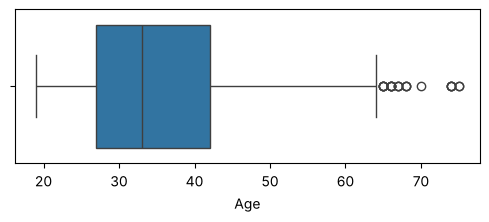

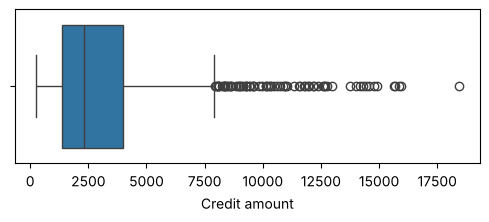

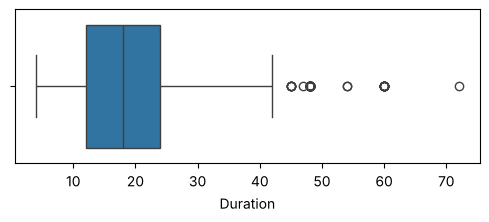

In [10]:
num_cols = ['Age', 'Credit amount', 'Duration']

for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(data=df_clean, x=col)
    plt.show()

Выбросы (точки за усами) видны во всех трёх количественных признаках, справа: пожилые заёмщики, очень крупные кредиты и очень длинные сроки. Сильнее всего выделяется `Credit amount`.

### Метод 3 стандартных отклонений (`Credit amount`)

Наблюдение считается выбросом, если оно отстоит от среднего больше чем на 3 стандартных отклонения.

In [11]:
mean_ca = df_clean['Credit amount'].mean()
std_ca = df_clean['Credit amount'].std()
left = mean_ca - 3 * std_ca
right = mean_ca + 3 * std_ca
print(left, right)

df_sigma = df_clean[df_clean['Credit amount'].between(left, right)].copy()
df_sigma.shape[0]

-5196.952627881323 11739.468627881322


975

### Метод 1.5·IQR (`Duration`)

Работаем с `df_sigma`. Выброс — значение вне интервала [Q1 − 1.5·IQR; Q3 + 1.5·IQR].

In [12]:
q1 = df_sigma['Duration'].quantile(0.25)
q3 = df_sigma['Duration'].quantile(0.75)
iqr = q3 - q1
left = q1 - 1.5 * iqr
right = q3 + 1.5 * iqr
print(q1, q3, iqr, left, right)

df_iqr = df_sigma[df_sigma['Duration'].between(left, right)].copy()
df_iqr.shape[0]

12.0 24.0 12.0 -6.0 42.0


917

- Методом 3σ удалено 25 кредитов дороже ≈ 11 739 марок (1000 → 975 строк).
- Методом 1.5·IQR удалено 58 кредитов сроком больше 42 месяцев (975 → 917 строк).
- Дальше работаем с `df_iqr` — **917 наблюдений**.

## Визуализация

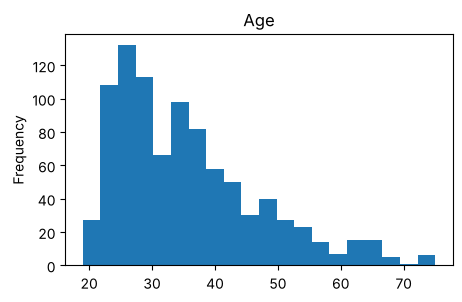

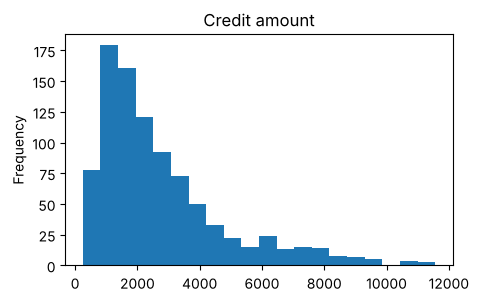

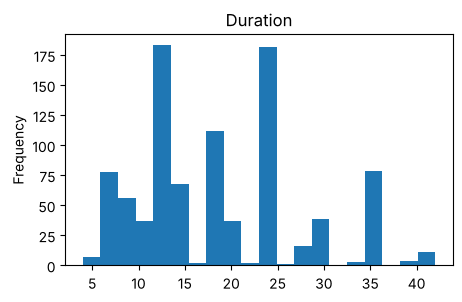

In [13]:
for col in num_cols:
    df_iqr[col].plot(kind='hist', bins=20, figsize=(5, 3), title=col)
    plt.show()

**Выводы по количественным признакам:**
- `Age` — распределение скошено вправо: основная масса заёмщиков 25–40 лет, пожилых мало. Не нормальное.
- `Credit amount` — сильная правосторонняя асимметрия: большинство кредитов до 4000 марок, крупные встречаются редко. Не нормальное.
- `Duration` — значения сгруппированы на «круглых» сроках (12, 18, 24, 36 месяцев), чаще всего 12 и 24 месяца; распределение тоже скошено вправо.

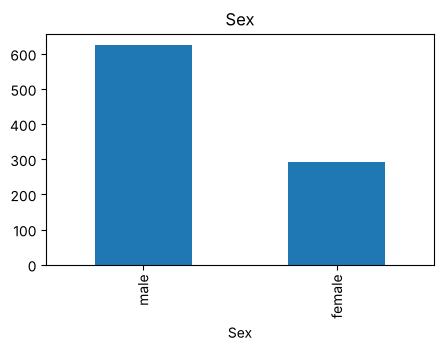

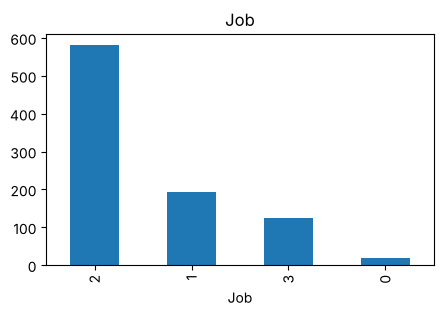

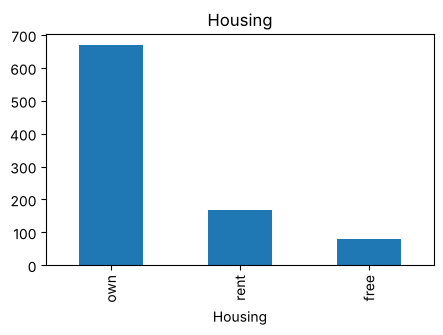

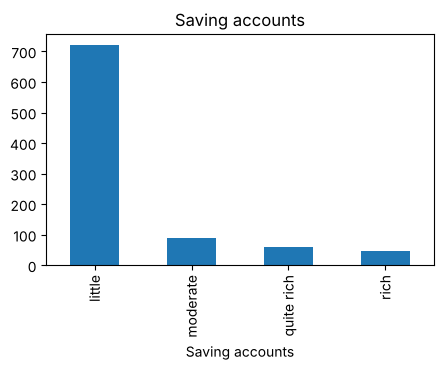

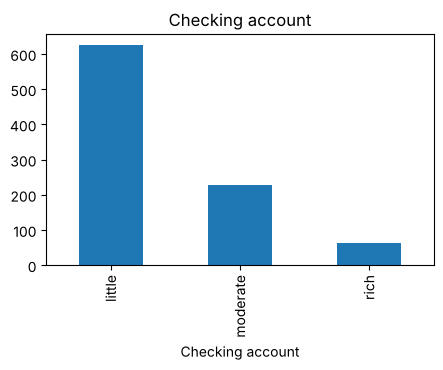

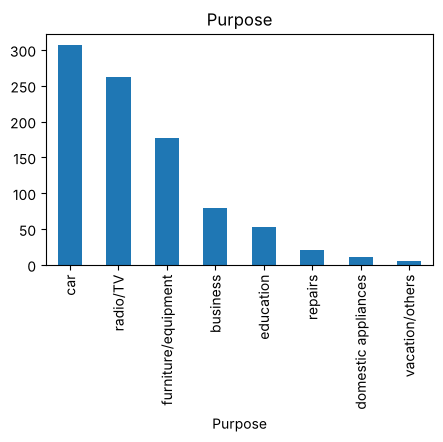

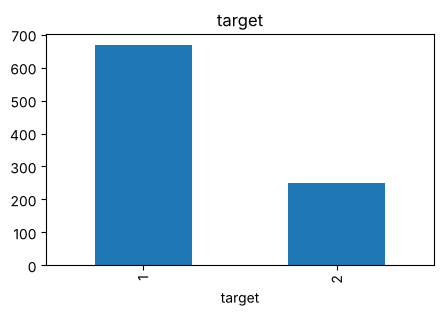

In [14]:
cat_cols = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose', 'target']

for col in cat_cols:
    df_iqr[col].value_counts().plot(kind='bar', figsize=(5, 3), title=col)
    plt.show()

**Выводы по категориальным признакам:**
- `Sex` — мужчин больше двух третей (≈ 68%).
- `Job` — преобладают квалифицированные работники (код 2, ≈ 63%), неквалифицированных нерезидентов (0) всего ≈ 2%.
- `Housing` — ≈ 73% живут в собственном жилье.
- `Saving accounts` и `Checking account` — после заполнения пропусков доминирует `little` (≈ 79% и ≈ 68%).
- `Purpose` — чаще всего берут кредит на автомобиль (≈ 34%) и радио/ТВ (≈ 29%); отпуск и бытовая техника — редкие цели.
- `target` — классы несбалансированы: хороших заёмщиков ≈ 73%, плохих ≈ 27%.

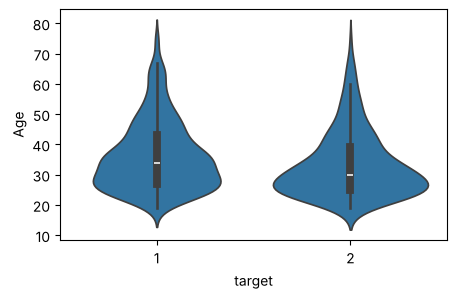

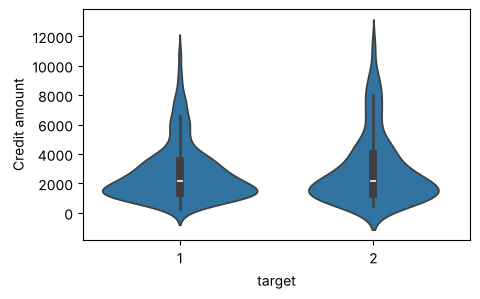

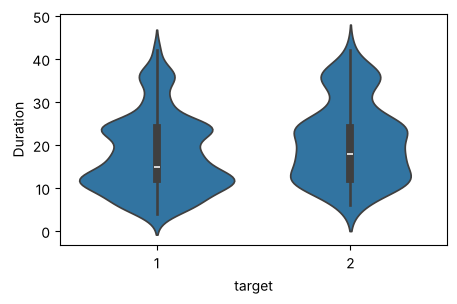

In [15]:
for col in num_cols:
    plt.figure(figsize=(5, 3))
    sns.violinplot(data=df_iqr, x='target', y=col)
    plt.show()

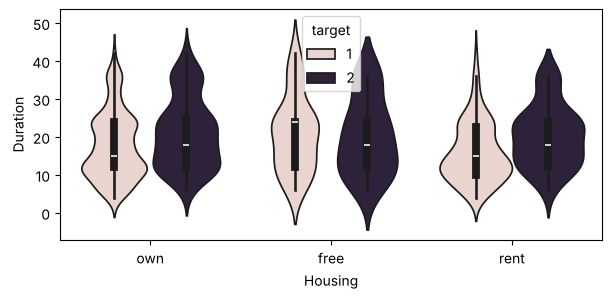

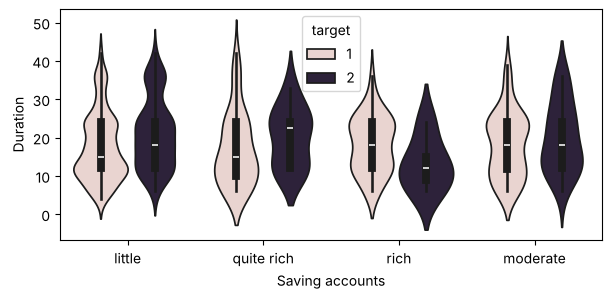

In [16]:
plt.figure(figsize=(7, 3))
sns.violinplot(data=df_iqr, x='Housing', y='Duration', hue='target')
plt.show()

plt.figure(figsize=(7, 3))
sns.violinplot(data=df_iqr, x='Saving accounts', y='Duration', hue='target')
plt.show()

In [17]:
df_iqr.groupby('target')[num_cols].median()

,Age,Credit amount,Duration
target,,,
1,34.0,2134.0,15.0
2,30.0,2134.5,18.0


**Выводы по скрипичным графикам:**
- `Duration` — у плохих заёмщиков распределение сдвинуто к более длинным срокам (медиана 18 мес. против 15 у хороших): чем дольше кредит, тем выше риск.
- `Age` — плохие заёмщики в среднем моложе (медиана 30 лет против 34), их распределение сильнее сосредоточено в 20–30 годах.
- `Credit amount` — формы распределений почти совпадают (медианы ≈ 2134 у обеих групп): после удаления выбросов сумма кредита слабо отличает хороших заёмщиков от плохих.
- `Housing` — у арендаторов и владельцев жилья плохие заёмщики берут кредиты на более длинный срок (медиана 18 против 15 мес.); у живущих бесплатно (`free`) наоборот — у хороших заёмщиков медианный срок больше (24 против 18 мес.), но эта группа малочисленна (79 человек).
- `Saving accounts` — при малых сбережениях (`little`) плохие заёмщики берут кредиты на более долгий срок; у богатых (`rich`) плохих заёмщиков мало, и их распределение неустойчиво.

## Описательные статистики

### Целевой признак

`target` — бинарный категориальный признак, поэтому для него считаем частоты, доли и моду. Среднее по кодам 1/2 смысла не имеет.

In [18]:
df_iqr['target'].mode()[0]

np.int64(1)

In [19]:
df_iqr['target'].value_counts()

target
1    667
2    250
Name: count, dtype: int64

In [20]:
# доля = частота / число наблюдений
(df_iqr['target'].value_counts() / df_iqr.shape[0]).round(3)

target
1    0.727
2    0.273
Name: count, dtype: float64

**Интерпретация:**
- Мода равна 1: типичный заёмщик в выборке — «хороший».
- Хороших заёмщиков 667 (≈ 72.7%), плохих — 250 (≈ 27.3%).
- Классы несбалансированы (примерно 3 : 1). Модель, которая всегда отвечает «хороший», уже даёт ≈ 73% правильных ответов, поэтому при оценке регрессии одной accuracy недостаточно.

### Предикторы

In [21]:
df_iqr[num_cols].describe().round(2)

,Age,Credit amount,Duration
count,917.00,917.00,917.00
mean,35.47,2776.10,18.56
std,11.37,2074.85,9.02
min,19.00,250.00,4.00
25%,27.00,1318.00,12.00
50%,33.00,2134.00,18.00
75%,42.00,3556.00,24.00
max,75.00,11560.00,42.00


In [22]:
df_iqr[num_cols].median()

Age                33.0
Credit amount    2134.0
Duration           18.0
dtype: float64

In [23]:
# межквартильный размах
df_iqr[num_cols].quantile(0.75) - df_iqr[num_cols].quantile(0.25)

Age                15.0
Credit amount    2238.0
Duration           12.0
dtype: float64

In [24]:
cat_pred = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
df_iqr[cat_pred].astype(str).describe()

,Sex,Job,Housing,Saving accounts,Checking account,Purpose
count,917,917,917,917,917,917
unique,2,4,3,4,3,8
top,male,2,own,little,little,car
freq,626,581,669,720,625,307


**Интерпретация количественных предикторов:**
- `Age`: средний возраст ≈ 35.5 года, медиана 33. Среднее больше медианы — правосторонняя асимметрия (есть немного пожилых заёмщиков). Половина заёмщиков в возрасте от 27 до 42 лет (IQR = 15).
- `Credit amount`: средняя сумма ≈ 2776 марок, медиана 2134. Большой разрыв между ними говорит о сильной асимметрии, поэтому типичный кредит лучше описывает медиана. Стандартное отклонение (≈ 2075) сопоставимо со средним — разброс большой.
- `Duration`: средний срок ≈ 18.6 мес., медиана 18; половина кредитов выдана на срок от 12 до 24 месяцев (IQR = 12).

**Интерпретация категориальных предикторов** (для них используются мода и частоты; `top` — мода, `freq` — её частота):
- Мода `Sex` — male (626 из 917), `Housing` — own (669), `Purpose` — car (307; всего 8 уникальных целей).
- Мода `Job` — 2 (квалифицированный работник, 581 человек).
- Мода `Saving accounts` и `Checking account` — little: у большинства заёмщиков небольшие сбережения и остатки на счетах.

## Перекодирование данных

Работаем с очищенными данными `df_iqr`. Целевую переменную переводим в формат 0/1, где **1 — плохой заёмщик** (событие, которое мы хотим предсказывать), 0 — хороший.

In [25]:
df_enc = df_iqr.copy()
df_enc['target'] = df_enc['target'].apply(lambda x: 1 if x == 2 else 0)
df_enc['target'].value_counts()

target
0    667
1    250
Name: count, dtype: int64

### One-Hot: бинарный признак `Sex`

In [26]:
df_enc = pd.get_dummies(df_enc, columns=['Sex'], drop_first=True, dtype=int)
df_enc.head()

,Age,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,target,Sex_male
0,67,2,own,little,little,1169,6,radio/TV,0,1
2,49,1,own,little,little,2096,12,education,0,1
3,45,2,free,little,little,7882,42,furniture/equipment,0,1
4,53,2,free,little,little,4870,24,car,1,1
5,35,1,free,little,little,9055,36,education,0,1


`drop_first=True` оставляет один столбец `Sex_male` (1 — мужчина, 0 — женщина). Второй столбец был бы лишним: он однозначно восстанавливается из первого.

### LabelEncoder: номинальные `Purpose` и `Housing`

In [27]:
le = LabelEncoder()
df_enc['Purpose'] = le.fit_transform(df_enc['Purpose'])
df_enc['Housing'] = le.fit_transform(df_enc['Housing'])
df_enc[['Purpose', 'Housing']].head()

,Purpose,Housing
0,5,1
2,3,1
3,4,0
4,1,0
5,3,0


LabelEncoder присваивает номера категориям по алфавиту (`Housing`: free = 0, own = 1, rent = 2), поэтому сами числа не несут смысла «больше/меньше».

### OrdinalEncoder: порядковые `Saving accounts` и `Checking account`

In [28]:
oe = OrdinalEncoder()
df_enc[['Saving accounts', 'Checking account']] = oe.fit_transform(
    df_enc[['Saving accounts', 'Checking account']])
df_enc[['Saving accounts', 'Checking account']].value_counts()

Saving accounts  Checking account
0.0              0.0                 499
                 1.0                 170
                 2.0                  51
1.0              0.0                  49
2.0              0.0                  46
1.0              1.0                  36
3.0              0.0                  31
                 1.0                  13
2.0              1.0                  10
1.0              2.0                   5
2.0              2.0                   4
3.0              2.0                   3
Name: count, dtype: int64

OrdinalEncoder нумерует категории по алфавиту. Для этих признаков алфавитный порядок совпадает со смысловым: little = 0 < moderate = 1 < quite rich = 2 < rich = 3 (для `Checking account`: little = 0 < moderate = 1 < rich = 2). Поэтому числа сохраняют порядок шкалы.

In [29]:
df_enc.head()

,Age,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,target,Sex_male
0,67,2,1,0.0,0.0,1169,6,5,0,1
2,49,1,1,0.0,0.0,2096,12,3,0,1
3,45,2,0,0.0,0.0,7882,42,4,0,1
4,53,2,0,0.0,0.0,4870,24,1,1,1
5,35,1,0,0.0,0.0,9055,36,3,0,1


## Корреляция

### Парная корреляция: `target` и `Duration`

`target` бинарный (0/1), `Duration` количественный. Коэффициент Пирсона для бинарной и количественной переменной называется точечно-бисериальной корреляцией.

In [30]:
df_enc[['target', 'Duration']].corr()

,target,Duration
target,1.000000,0.155295
Duration,0.155295,1.000000


**Интерпретация:**
- r ≈ 0.16 > 0: связь **прямая** — чем длиннее срок кредита, тем чаще заёмщик оказывается плохим (target = 1).
- По модулю коэффициент меньше 0.3, связь **слабая**: срок объясняет лишь небольшую часть различий между заёмщиками.

### Корреляционная матрица

Используем коэффициент **Спирмена**: он оценивает монотонную связь и подходит для порядковых (`Job`, `Saving accounts`, `Checking account`) и бинарных признаков, а также устойчив к асимметрии распределений.

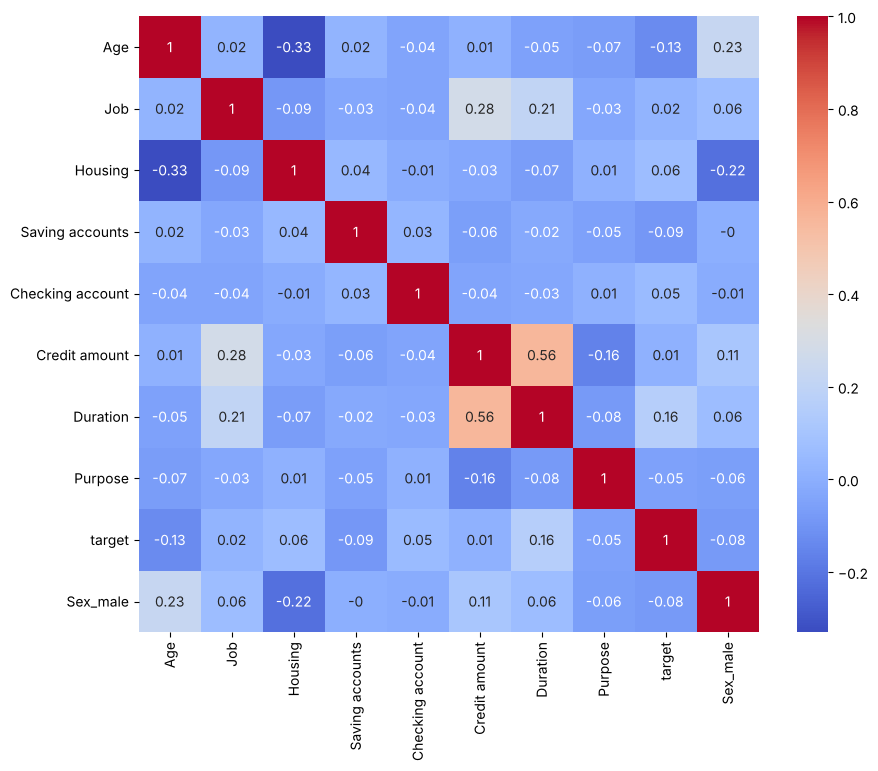

In [31]:
corr = df_enc.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr.round(2), annot=True, cmap='coolwarm')
plt.show()

In [32]:
corr['target'].drop('target').sort_values(key=abs, ascending=False).head(5)

Duration           0.157291
Age               -0.131547
Saving accounts   -0.085469
Sex_male          -0.082421
Housing            0.058990
Name: target, dtype: float64

**Топ-5 признаков по силе связи с `target`:**
1. `Duration` (+0.16) — чем длиннее срок, тем выше риск.
2. `Age` (−0.13) — чем старше заёмщик, тем ниже риск.
3. `Saving accounts` (−0.09) — чем больше сбережения, тем ниже риск.
4. `Sex_male` (−0.08) — у мужчин риск немного ниже.
5. `Housing` (+0.06) — связь очень слабая; кроме того, это номинальный признак с кодами LabelEncoder, поэтому знак коэффициента интерпретировать нельзя.

Все связи с целевой переменной слабые (|ρ| < 0.2), поэтому от модели не стоит ждать высокого качества. Сильнее всего коррелируют между собой предикторы `Credit amount` и `Duration` (ρ ≈ 0.56): крупные кредиты берут на более долгий срок.

## Масштабирование данных

In [33]:
df_scaled = df_enc.copy()
stsc = StandardScaler()
df_scaled[num_cols] = stsc.fit_transform(df_scaled[num_cols])
df_scaled[num_cols].describe().round(2)

,Age,Credit amount,Duration
count,917.00,917.00,917.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.45,-1.22,-1.61
25%,-0.75,-0.70,-0.73
50%,-0.22,-0.31,-0.06
75%,0.57,0.38,0.60
max,3.48,4.24,2.60


После `StandardScaler` у каждого количественного признака среднее равно 0, а стандартное отклонение — 1: z = (x − среднее) / σ. Теперь признаки в разных единицах (годы, марки, месяцы) сопоставимы, и коэффициенты регрессии при них можно сравнивать между собой.

## Регрессия

**Модель:** мы хотим построить модель **бинарной логистической регрессии**, которая предсказывает вероятность того, что заёмщик окажется плохим (`target = 1`), по его возрасту, сумме и сроку кредита, полу, квалификации, уровню сбережений и остатку на текущем счёте.

В модель не включены `Purpose` и `Housing`: это номинальные признаки, закодированные LabelEncoder, и у их номеров нет порядка, поэтому один коэффициент при них не имел бы смысла.

In [34]:
x_cols = ['Age', 'Credit amount', 'Duration', 'Sex_male', 'Job',
          'Saving accounts', 'Checking account']
X = df_scaled[x_cols]
y = df_scaled['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state=42,
    test_size=0.3
)
X_train.shape, X_test.shape

((641, 7), (276, 7))

Выборка разделена в пропорции 70 / 30 (`test_size=0.3`): на 641 наблюдении модель обучается, на 276 — проверяется. `random_state=42` делает разбиение воспроизводимым.

In [35]:
model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)

pd.Series(model.coef_.flatten(), index=model.feature_names_in_).round(3)

Age                -0.079
Credit amount      -0.172
Duration            0.476
Sex_male           -0.585
Job                -0.035
Saving accounts    -0.289
Checking account    0.188
dtype: float64

In [36]:
model.intercept_.round(3)

array([0.449])

In [37]:
# отношение шансов: во сколько раз меняются шансы при росте признака на 1
np.exp(pd.Series(model.coef_.flatten(), index=model.feature_names_in_)).round(3)

Age                 0.924
Credit amount       0.842
Duration            1.609
Sex_male            0.557
Job                 0.966
Saving accounts     0.749
Checking account    1.207
dtype: float64

`class_weight='balanced'` делает ошибки на редком классе (плохих заёмщиков) «дороже» при обучении. Без этого параметра модель почти всегда предсказывает «хороший», потому что хороших заёмщиков в 3 раза больше, и находит лишь ≈ 7% плохих заёмщиков — для оценки риска такая модель бесполезна.

**Уравнение обученной модели:**

$$\ln\frac{p}{1-p} = 0.449 - 0.079\cdot Age - 0.172\cdot CreditAmount + 0.476\cdot Duration - 0.585\cdot Sex\_male - 0.035\cdot Job - 0.289\cdot SavingAccounts + 0.188\cdot CheckingAccount$$

где p — вероятность того, что заёмщик плохой; `Age`, `CreditAmount` и `Duration` стандартизированы.

**Интерпретация параметров** (в логистической регрессии коэффициент — это изменение логарифма шансов, а e^коэффициент — во сколько раз меняются шансы оказаться плохим заёмщиком при прочих равных):
- **Свободный член (0.449):** логарифм шансов для «базового» заёмщика — женщины среднего возраста, со средними суммой и сроком кредита, Job = 0, минимальными сбережениями и остатком на счёте. Из-за `class_weight='balanced'` его значение смещено и не равно реальной доле плохих заёмщиков.
- **Age (−0.079):** рост возраста на 1 стандартное отклонение (≈ 11 лет) уменьшает шансы оказаться плохим заёмщиком в ≈ 0.92 раза (на ≈ 8%).
- **Credit amount (−0.172):** рост суммы на 1 стандартное отклонение (≈ 2075 марок) уменьшает шансы в ≈ 0.84 раза (на ≈ 16%) при том же сроке кредита.
- **Duration (+0.476):** рост срока на 1 стандартное отклонение (≈ 9 мес.) увеличивает шансы в ≈ 1.61 раза (на ≈ 61%) — самый сильный количественный фактор.
- **Sex_male (−0.585):** у мужчин шансы оказаться плохим заёмщиком в ≈ 0.56 раза ниже, чем у женщин.
- **Job (−0.035):** переход на следующий уровень квалификации уменьшает шансы в ≈ 0.97 раза — эффект почти нулевой.
- **Saving accounts (−0.289):** каждый следующий уровень сбережений уменьшает шансы в ≈ 0.75 раза (на ≈ 25%).
- **Checking account (+0.188):** следующий уровень остатка на счёте увеличивает шансы в ≈ 1.21 раза. Эффект неожиданный и, вероятно, искажён заполнением 40% пропусков модой.

In [38]:
pred_class = model.predict(X_test)
pred_proba = model.predict_proba(X_test)[:, 1]

(
    round(accuracy_score(y_test, pred_class), 3),
    round(precision_score(y_test, pred_class), 3),
    round(recall_score(y_test, pred_class), 3),
    round(f1_score(y_test, pred_class), 3),
    round(roc_auc_score(y_test, pred_proba), 3)
)

(0.591, 0.351, 0.622, 0.449, 0.615)

In [39]:
# строки - факт (0, 1), столбцы - предсказание (0, 1)
pd.DataFrame(confusion_matrix(y_test, pred_class))

,0,1
0,117,85
1,28,46


**Интерпретация метрик качества** (тестовая выборка, 276 заёмщиков):
- **Accuracy ≈ 0.59:** модель верно классифицирует 59% заёмщиков. Это ниже доли большинства (≈ 73%), но accuracy здесь вводит в заблуждение: модель «всегда хороший» даёт 73%, не находя ни одного плохого заёмщика.
- **Recall ≈ 0.62:** модель находит 62% действительно плохих заёмщиков (46 из 74). Для банка это главная метрика, потому что пропущенный плохой заёмщик стоит дороже всего.
- **Precision ≈ 0.35:** из заёмщиков, которых модель назвала плохими, плохими оказались только 35% — много «ложных тревог» (85 хороших заёмщиков отмечены как плохие).
- **F1 ≈ 0.45:** баланс precision и recall ниже среднего.
- **ROC-AUC ≈ 0.62:** модель ранжирует заёмщиков лучше случайного угадывания (0.5), но качество невысокое — ожидаемо, учитывая слабые корреляции признаков с target.

## Тестирование гипотез

Уровень значимости во всех тестах α = 0.05. Используем очищенные данные `df_iqr` в исходных единицах измерения (без масштабирования).

### Тест Шапиро–Уилка (проверка нормальности)

**Формулировка:** проверяем, распределены ли нормально возраст, сумма и срок кредита. От этого зависит выбор параметрического или непараметрического теста.

- H₀: признак распределён нормально
- H₁: распределение признака отличается от нормального

In [40]:
for col in num_cols:
    res = stats.shapiro(df_iqr[col])
    print(col, res.pvalue)

Age 3.52265759126675e-22
Credit amount 2.409400794478263e-29
Duration 4.9382825409564436e-20


**Интерпретация:**
- У всех трёх признаков p-value < 0.05 → H₀ отвергаем: ни один признак не распределён нормально.
- Для тестов о средних это не критично: выборка большая (n = 917), и по центральной предельной теореме выборочное среднее распределено приблизительно нормально. Для сравнения групп по `Duration` дополнительно используем непараметрический тест Манна–Уитни.

### 1. z-тест для среднего

**Формулировка:** хотим проверить гипотезу о том, что средняя сумма кредита равна 3000 марок, если считать, что выборочная дисперсия равна дисперсии генеральной совокупности.

- H₀: μ = 3000
- H₁: μ ≠ 3000

In [41]:
res = ztest(df_iqr['Credit amount'], value=3000)
res

(np.float64(-3.267822806779086), np.float64(0.0010837819513087228))

**Интерпретация:**
- `ztest` возвращает пару (статистика, p-value). p-value ≈ 0.001 < 0.05 → H₀ отвергаем.
- Средняя сумма кредита статистически значимо отличается от 3000 марок: выборочное среднее ≈ 2776, статистика z < 0, то есть средняя сумма меньше 3000.

### 2. Одновыборочный t-тест

**Формулировка:** хотим проверить гипотезу о том, что средний возраст заёмщика равен 35 годам; дисперсия генеральной совокупности неизвестна.

- H₀: μ = 35
- H₁: μ ≠ 35

In [42]:
res = stats.ttest_1samp(df_iqr['Age'], 35)
res.pvalue

np.float64(0.21199583339525307)

**Интерпретация:**
- p-value ≈ 0.21 > 0.05 → нет оснований отвергнуть H₀.
- Данные не противоречат тому, что средний возраст заёмщика равен 35 годам (выборочное среднее ≈ 35.5).

### 3. t-тест для двух независимых выборок

**Формулировка:** хотим проверить гипотезу о том, что средняя сумма кредита у хороших и плохих заёмщиков одинакова. Выборки независимы: каждый заёмщик относится только к одной группе.

- H₀: μ_хорошие = μ_плохие
- H₁: μ_хорошие ≠ μ_плохие

In [43]:
res = stats.ttest_ind(
    df_iqr[df_iqr['target'] == 1]['Credit amount'],
    df_iqr[df_iqr['target'] == 2]['Credit amount']
)
res.pvalue

np.float64(0.10935451625586994)

**Интерпретация:**
- Нормальность нарушена (Шапиро–Уилк), но группы большие (667 и 250 наблюдений), поэтому по ЦПТ t-тест применим.
- p-value ≈ 0.11 > 0.05 → нет оснований отвергнуть H₀: средняя сумма кредита у хороших (≈ 2709) и плохих (≈ 2955) заёмщиков статистически значимо не различается.

### 4. Парный t-тест

**Формулировка:** парный t-тест сравнивает два измерения **одних и тех же** объектов (например, сумму долга заёмщика до и после реструктуризации).

- H₀: μ_d = 0 (средняя разность пар равна нулю)
- H₁: μ_d ≠ 0

**Интерпретация:** в наших данных у каждого заёмщика каждый признак измерен **один раз**, связанных пар наблюдений нет. Предпосылка парного теста не выполняется, поэтому применить его к этим данным нельзя.

### 5. z-тест для доли

**Формулировка:** хотим проверить гипотезу о том, что доля плохих заёмщиков в генеральной совокупности равна 30% (такую долю заявляют составители исходного датасета).

- H₀: p = 0.3
- H₁: p ≠ 0.3

In [44]:
count_bad = df_iqr[df_iqr['target'] == 2].shape[0]
nobs_all = df_iqr.shape[0]

res = proportions_ztest(count_bad, nobs_all, value=0.3)
res[1]

np.float64(0.06269632442594494)

**Интерпретация:**
- p-value ≈ 0.063 > 0.05 → нет оснований отвергнуть H₀.
- Выборочная доля плохих заёмщиков (250 / 917 ≈ 27.3%) статистически значимо не отличается от 30%. Доля ниже исходных 30%, потому что при удалении выбросов исключены 83 крупных и длинных кредита, из которых ≈ 60% — плохие.

### 6. Хи-квадрат на независимость

**Формулировка:** хотим проверить, связаны ли тип жилья (`Housing`) и кредитный риск (`target`).

- H₀: `Housing` и `target` независимы
- H₁: `Housing` и `target` зависимы

In [45]:
t = df_iqr.pivot_table(
    index='Housing',
    columns='target',
    values='Age',
    aggfunc='count'
)
t

target,1,2
Housing,,
free,54,25
own,505,164
rent,108,61


In [46]:
res = stats.chi2_contingency(t)
res.pvalue, res.expected_freq.min()

(np.float64(0.0068686864628339965), np.float64(21.53762268266085))

**Интерпретация:**
- Предпосылка теста выполнена: все ожидаемые частоты больше 5 (минимальная ≈ 21.5).
- p-value ≈ 0.007 < 0.05 → H₀ отвергаем: тип жилья и кредитный риск связаны.
- Среди арендаторов доля плохих заёмщиков ≈ 36% (61 из 169), среди владельцев жилья — ≈ 25% (164 из 669).

### 7. Тест Манна–Уитни

**Формулировка:** `Duration` распределён не нормально (тест Шапиро–Уилка), поэтому сравниваем сроки кредита у хороших и плохих заёмщиков непараметрическим тестом.

- H₀: распределения `Duration` у хороших и плохих заёмщиков одинаковы
- H₁: распределения `Duration` у хороших и плохих заёмщиков различаются

In [47]:
res = stats.mannwhitneyu(
    df_iqr[df_iqr['target'] == 1]['Duration'],
    df_iqr[df_iqr['target'] == 2]['Duration']
)
res.pvalue

np.float64(1.9326419305468214e-06)

**Интерпретация:**
- p-value ≈ 1.9·10⁻⁶ < 0.05 → H₀ отвергаем.
- Сроки кредита у хороших и плохих заёмщиков статистически значимо различаются: у плохих они длиннее (медиана 18 мес. против 15). Это согласуется с корреляционным анализом и с положительным коэффициентом `Duration` в регрессии.

## Общий вывод

- После очистки (пропуски → мода, удаление выбросов методами 3σ и 1.5·IQR) осталось 917 заёмщиков, из них ≈ 27% плохих.
- Риск невозврата сильнее всего связан со сроком кредита (чем дольше, тем выше риск), возрастом (молодые рискованнее) и сбережениями (чем больше, тем ниже риск); тип жилья тоже связан с риском (тест хи-квадрат).
- Сумма кредита после удаления выбросов почти не отличает хороших заёмщиков от плохих (t-тест, корреляция ≈ 0).
- Логистическая регрессия находит ≈ 62% плохих заёмщиков при ROC-AUC ≈ 0.62: качество невысокое, потому что все связи признаков с целевой переменной слабые.